In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan plot
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
file_path = r'C:\Pupuk\data\Crop recommendation dataset.csv'
df = pd.read_csv(file_path)

In [3]:
df.head()

,CROPS,TYPE_OF_CROP,SOIL,SEASON,SOWN,HARVESTED,WATER_SOURCE,SOIL_PH,SOIL_PH_HIGH,CROPDURATION,...,WATERREQUIRED,WATERREQUIRED_MAX,RELATIVE_HUMIDITY,RELATIVE_HUMIDITY_MAX,N,N_MAX,P,P_MAX,K,K_MAX
0,rice,cereals,Alluvial soil,kharif,Jun,Sep,irrigated,7.6,8.0,116.9,...,2462.3,2500,73.8,80,82.4,100,40.7,60,42.2,60
1,rice,cereals,Loamy soil,kharif,Jul,Oct,rainfed,6.2,8.0,117.9,...,1237.5,2500,60.9,80,90.5,100,51.3,60,46.2,60
2,rice,cereals,Clay soil,kharif,Jun,Sep,irrigated,6.7,8.0,117.7,...,1075.1,2500,67.5,80,86.2,100,50.7,60,44.4,60
3,rice,cereals,Alluvial soil,kharif,Jul,Oct,rainfed,6.1,8.0,149.8,...,1549.9,2500,73.6,80,91.3,100,51.3,60,44.5,60
4,rice,cereals,Loamy soil,kharif,Jun,Sep,irrigated,8.0,8.0,131.7,...,1306.4,2500,60.3,80,81.3,100,48.6,60,51.0,60


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57000 entries, 0 to 56999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CROPS                  57000 non-null  object 
 1   TYPE_OF_CROP           57000 non-null  object 
 2   SOIL                   57000 non-null  object 
 3   SEASON                 57000 non-null  object 
 4   SOWN                   57000 non-null  object 
 5   HARVESTED              57000 non-null  object 
 6   WATER_SOURCE           57000 non-null  object 
 7   SOIL_PH                57000 non-null  float64
 8   SOIL_PH_HIGH           57000 non-null  float64
 9   CROPDURATION           57000 non-null  float64
 10  CROPDURATION_MAX       57000 non-null  int64  
 11  TEMP                   57000 non-null  float64
 12  MAX_TEMP               57000 non-null  int64  
 13  WATERREQUIRED          57000 non-null  float64
 14  WATERREQUIRED_MAX      57000 non-null  int64  
 15  RE

In [5]:
print(df.isnull().sum())

CROPS                    0
TYPE_OF_CROP             0
SOIL                     0
SEASON                   0
SOWN                     0
HARVESTED                0
WATER_SOURCE             0
SOIL_PH                  0
SOIL_PH_HIGH             0
CROPDURATION             0
CROPDURATION_MAX         0
TEMP                     0
MAX_TEMP                 0
WATERREQUIRED            0
WATERREQUIRED_MAX        0
RELATIVE_HUMIDITY        0
RELATIVE_HUMIDITY_MAX    0
N                        0
N_MAX                    0
P                        0
P_MAX                    0
K                        0
K_MAX                    0
dtype: int64


In [6]:
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']
df[sensor_cols].describe()

,N,P,K,SOIL_PH,TEMP,RELATIVE_HUMIDITY
count,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000
mean,81.284277,48.197891,56.605086,6.624367,24.757740,71.197588
std,33.786202,17.160902,27.438288,0.649972,5.862506,23.158554
min,20.000000,20.000000,20.000000,5.000000,5.000000,15.000000
25%,56.600000,34.975000,34.900000,6.200000,21.100000,64.400000
50%,80.500000,47.700000,50.500000,6.600000,24.800000,78.200000
75%,100.800000,58.000000,75.400000,7.000000,28.000000,85.300000
max,199.900000,100.000000,149.900000,9.000000,47.000000,100.000000


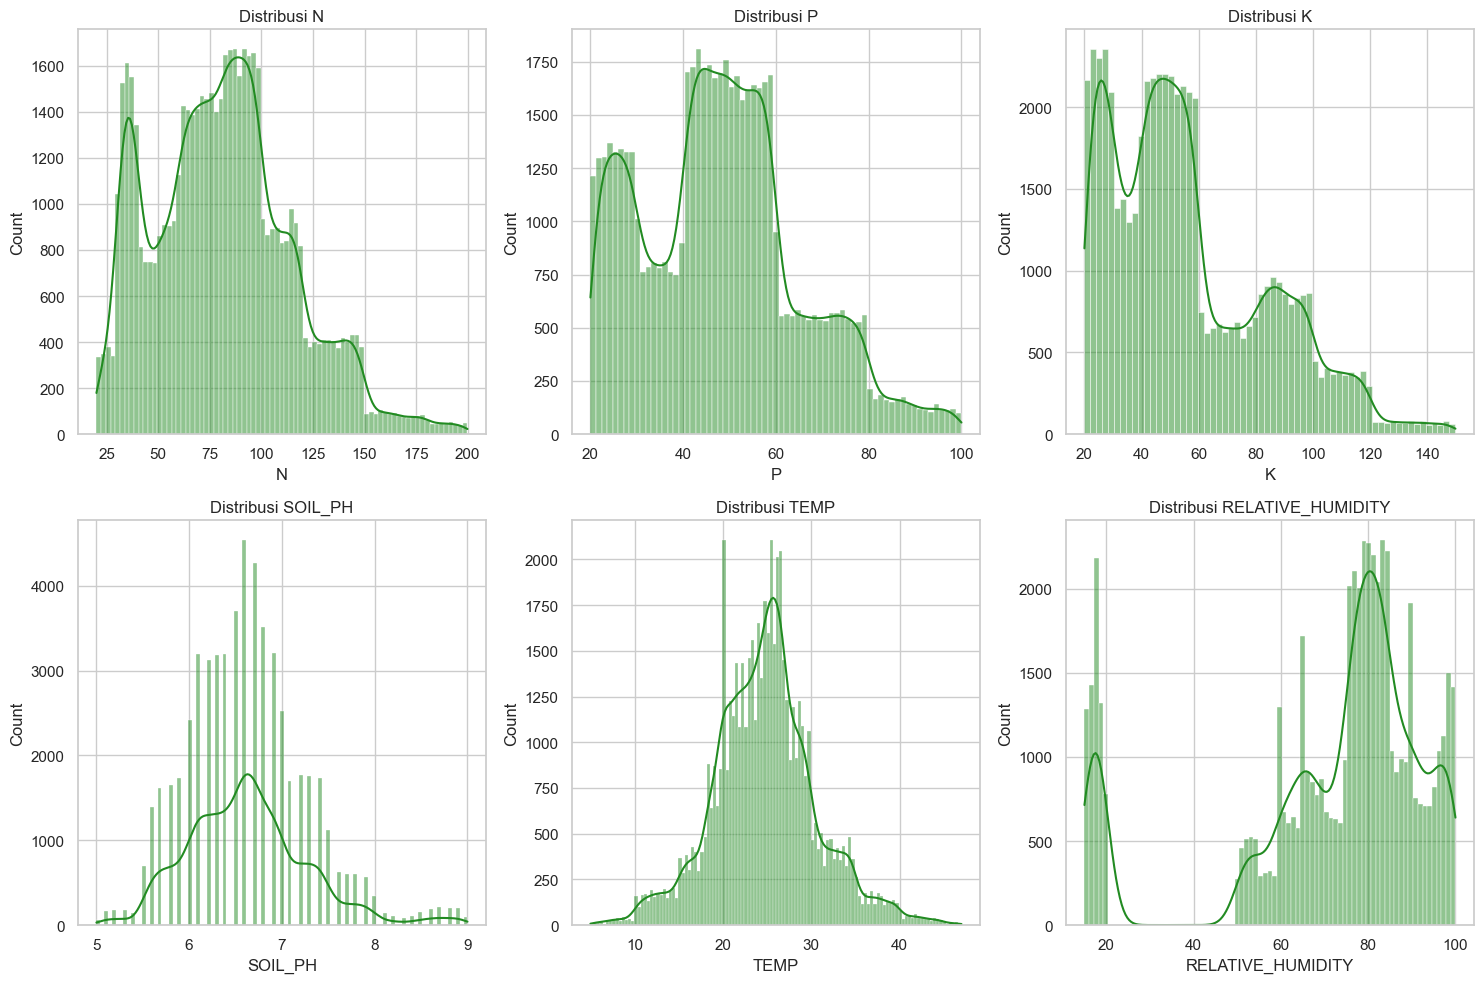

In [7]:
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']

plt.figure(figsize=(15, 10))
for i, col in enumerate(sensor_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, color='forestgreen')
    plt.title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

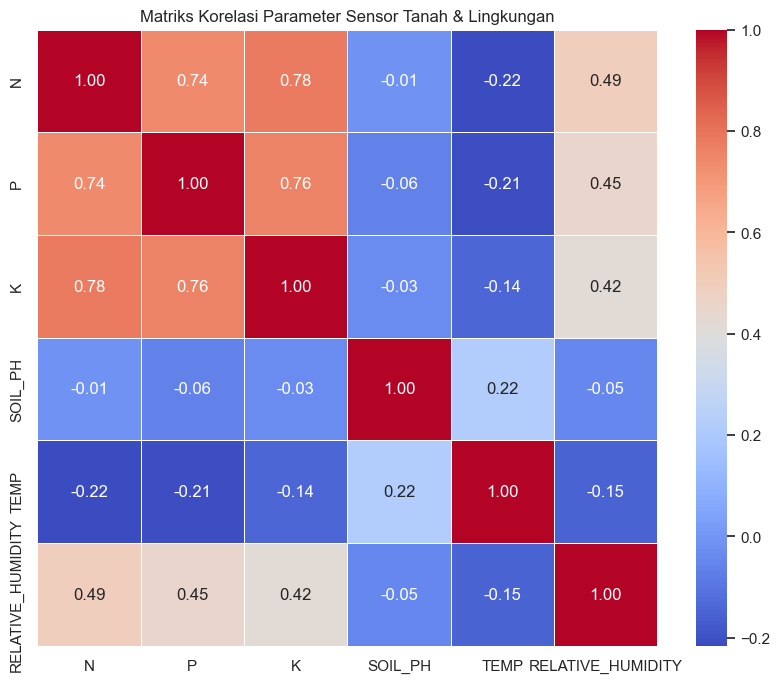

In [8]:
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']

plt.figure(figsize=(10, 8))
corr_matrix = df[sensor_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Parameter Sensor Tanah & Lingkungan')
plt.show()

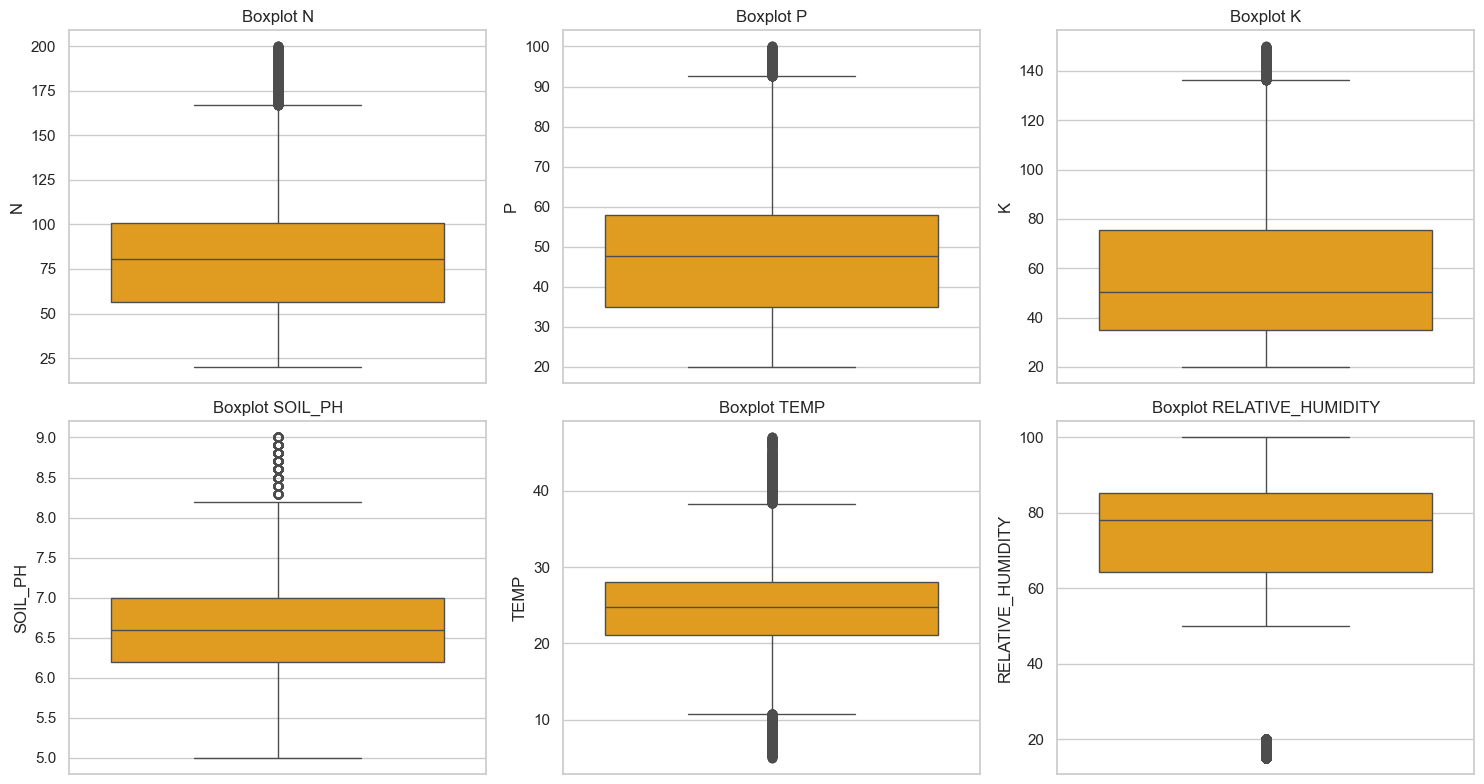

In [9]:
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']

plt.figure(figsize=(15, 8))
for i, col in enumerate(sensor_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='orange')
    plt.title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

# Data Preprocessing

In [10]:
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']

df_clean = df[sensor_cols].drop_duplicates().reset_index(drop=True)
print(f"Ukuran data setelah pembersihan: {df_clean.shape}")
df_clean.head()

Ukuran data setelah pembersihan: (57000, 6)


,N,P,K,SOIL_PH,TEMP,RELATIVE_HUMIDITY
0,82.4,40.7,42.2,7.6,26.9,73.8
1,90.5,51.3,46.2,6.2,35.8,60.9
2,86.2,50.7,44.4,6.7,34.9,67.5
3,91.3,51.3,44.5,6.1,28.3,73.6
4,81.3,48.6,51.0,8.0,26.3,60.3


In [11]:
# Cell 11 (Revisi Final): Pelabelan Berbasis 6 Fitur Sensor (NPK + Koreksi pH, Suhu, & Kelembapan)
faktor_ph = 1 - (np.abs(df_clean['SOIL_PH'] - 6.5) / 10)
faktor_iklim = 1 - (np.abs(df_clean['TEMP'] - 25.0) / 100) - (np.abs(df_clean['RELATIVE_HUMIDITY'] - 75.0) / 200)

# Menghitung Skor Hara Efektif dari gabungan N, P, K yang dikoreksi pH, Suhu, dan Kelembapan
df_clean['SKOR_HARA_EFEKTIF'] = (0.30 * df_clean['N'] + 0.35 * df_clean['P'] + 0.35 * df_clean['K']) * faktor_ph * faktor_iklim

# Membagi menjadi 3 Kelas Status Kesuburan secara seimbang (Rendah, Sedang, Tinggi)
df_clean['STATUS_HARA'] = pd.qcut(df_clean['SKOR_HARA_EFEKTIF'], q=3, labels=['Hara_Rendah', 'Hara_Sedang', 'Hara_Tinggi']).astype(str)

# Mapping ke Standar BPSI (Mencakup Pilihan Pupuk Majemuk & Pupuk Tunggal)
paket_bpsi = {
    'Hara_Rendah': 'Dosis Tinggi -> Majemuk: NPK 15-10-12 (400 kg/ha) + Urea (225 kg/ha) | Tunggal: Urea 350, SP-36 94, KCl 94 kg/ha',
    'Hara_Sedang': 'Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 75, KCl 75 kg/ha',
    'Hara_Tinggi': 'Dosis Rendah -> Majemuk: NPK 15-10-12 (250 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 56, KCl 56 kg/ha'
}

df_clean['REKOMENDASI_PUPUK'] = df_clean['STATUS_HARA'].map(paket_bpsi)
df_clean.to_csv(r"C:\Pupuk\data\Crop_recommendation_labeled_BPSI.csv", index=False)

# Menampilkan distribusi kelas baru yang sudah seimbang tanpa SMOTE
pd.DataFrame({
    'Jumlah_Sampel': df_clean['REKOMENDASI_PUPUK'].value_counts(),
    'Persentase (%)': (df_clean['REKOMENDASI_PUPUK'].value_counts(normalize=True) * 100).round(2)
})

,Jumlah_Sampel,Persentase (%)
REKOMENDASI_PUPUK,,
"Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 75, KCl 75 kg/ha",19000,33.33
"Dosis Tinggi -> Majemuk: NPK 15-10-12 (400 kg/ha) + Urea (225 kg/ha) | Tunggal: Urea 350, SP-36 94, KCl 94 kg/ha",19000,33.33
"Dosis Rendah -> Majemuk: NPK 15-10-12 (250 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 56, KCl 56 kg/ha",19000,33.33


In [12]:
! pip install shap


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Modelling

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import shap

c:\Users\tuf\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Random Forest

In [14]:
# Menentukan Fitur (X) dan Target (y) dari data bersih berlabel
sensor_cols = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY']
X = df_clean[sensor_cols]
y = df_clean['STATUS_HARA']

# Membagi data menjadi 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Jumlah Data Training : {X_train.shape[0]} baris")
print(f"Jumlah Data Testing  : {X_test.shape[0]} baris")

Jumlah Data Training : 45600 baris
Jumlah Data Testing  : 11400 baris


In [15]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
y_pred_rf = rf_model.predict(X_test)
print(f"Akurasi Model Random Forest: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")
print("Laporan Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred_rf))

Akurasi Model Random Forest: 97.06%

Laporan Klasifikasi (Classification Report):
              precision    recall  f1-score   support

 Hara_Rendah       0.99      0.97      0.98      3800
 Hara_Sedang       0.94      0.97      0.96      3800
 Hara_Tinggi       0.98      0.97      0.98      3800

    accuracy                           0.97     11400
   macro avg       0.97      0.97      0.97     11400
weighted avg       0.97      0.97      0.97     11400



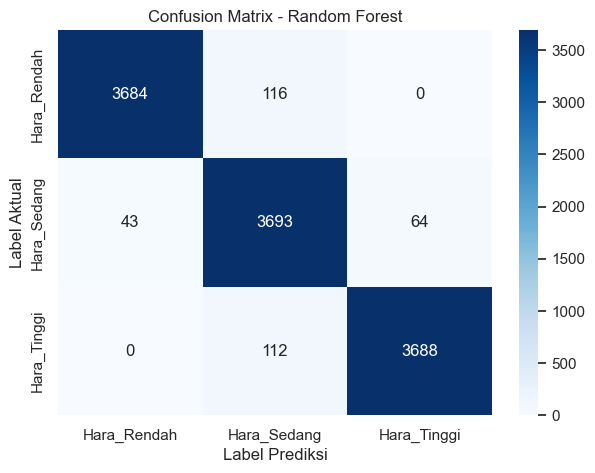

In [17]:
plt.figure(figsize=(7, 5))
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=rf_model.classes_, yticklabels=rf_model.classes_)
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('Label Aktual')
plt.xlabel('Label Prediksi')
plt.show()

C:\Users\tuf\AppData\Local\Temp\ipykernel_22372\1095209395.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances_rf[indices_rf], y=X.columns[indices_rf], palette='viridis')


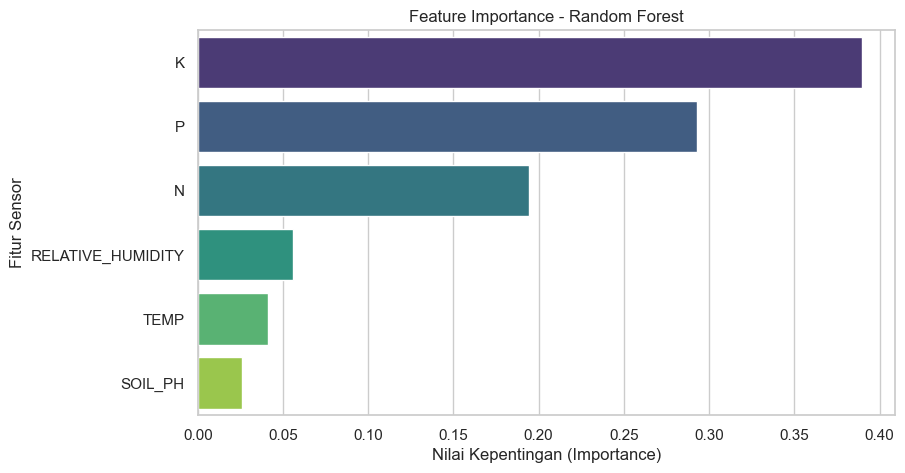

In [18]:
plt.figure(figsize=(9, 5))
importances_rf = rf_model.feature_importances_
indices_rf = np.argsort(importances_rf)[::-1]
sns.barplot(x=importances_rf[indices_rf], y=X.columns[indices_rf], palette='viridis')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Nilai Kepentingan (Importance)')
plt.ylabel('Fitur Sensor')
plt.show()

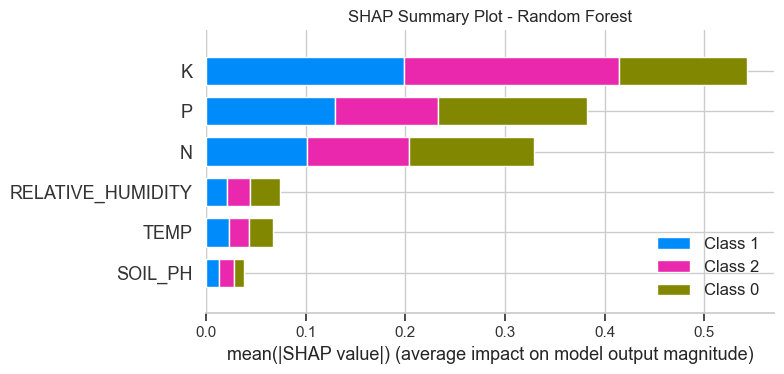

In [19]:
explainer_rf = shap.TreeExplainer(rf_model)
shap_values_rf = explainer_rf.shap_values(X_test)

plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot - Random Forest")
shap.summary_plot(shap_values_rf, X_test, plot_type="bar")

Gradient boosting

In [20]:
gb_model = GradientBoostingClassifier(
    n_estimators=100, 
    max_depth=3,          # Kedalaman default pohon boosting yang setara
    random_state=42
)
gb_model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [21]:
y_pred_gb = gb_model.predict(X_test)
print(f"Akurasi Model Gradient Boosting: {accuracy_score(y_test, y_pred_gb) * 100:.2f}%\n")
print("Laporan Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred_gb))

Akurasi Model Gradient Boosting: 96.27%

Laporan Klasifikasi (Classification Report):
              precision    recall  f1-score   support

 Hara_Rendah       0.99      0.96      0.97      3800
 Hara_Sedang       0.92      0.97      0.95      3800
 Hara_Tinggi       0.98      0.96      0.97      3800

    accuracy                           0.96     11400
   macro avg       0.96      0.96      0.96     11400
weighted avg       0.96      0.96      0.96     11400



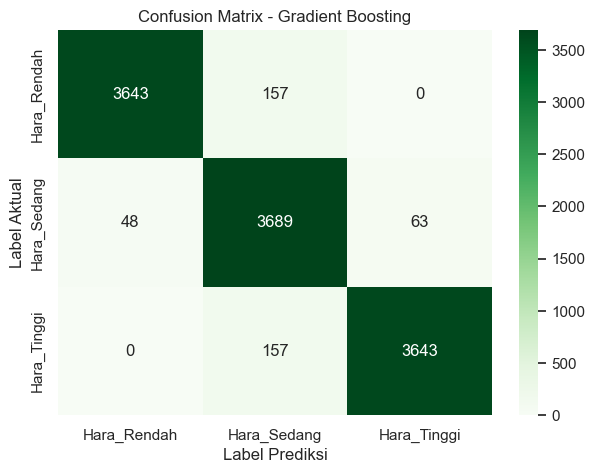

In [22]:
plt.figure(figsize=(7, 5))
cm_gb = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', xticklabels=gb_model.classes_, yticklabels=gb_model.classes_)
plt.title('Confusion Matrix - Gradient Boosting')
plt.ylabel('Label Aktual')
plt.xlabel('Label Prediksi')
plt.show()

C:\Users\tuf\AppData\Local\Temp\ipykernel_22372\3888186453.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances_gb[indices_gb], y=X.columns[indices_gb], palette='crest')


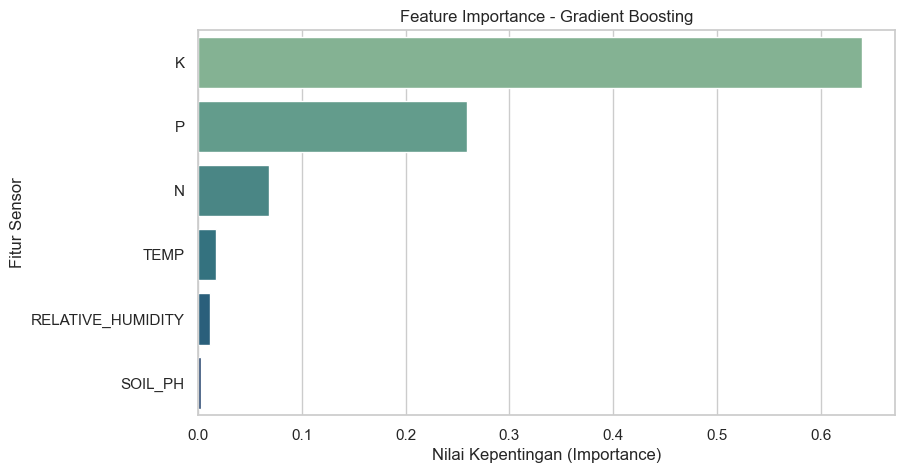

In [23]:
plt.figure(figsize=(9, 5))
importances_gb = gb_model.feature_importances_
indices_gb = np.argsort(importances_gb)[::-1]
sns.barplot(x=importances_gb[indices_gb], y=X.columns[indices_gb], palette='crest')
plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Nilai Kepentingan (Importance)')
plt.ylabel('Fitur Sensor')
plt.show()

Support Vector Machine

In [24]:
svm_model = SVC(kernel='rbf', C=1.0, class_weight='balanced', random_state=42, probability=True)
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [25]:
y_pred_svm = svm_model.predict(X_test)
print(f"Akurasi Model SVM: {accuracy_score(y_test, y_pred_svm) * 100:.2f}%\n")
print("Laporan Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred_svm))

Akurasi Model SVM: 95.18%

Laporan Klasifikasi (Classification Report):
              precision    recall  f1-score   support

 Hara_Rendah       0.99      0.95      0.97      3800
 Hara_Sedang       0.90      0.96      0.93      3800
 Hara_Tinggi       0.97      0.95      0.96      3800

    accuracy                           0.95     11400
   macro avg       0.95      0.95      0.95     11400
weighted avg       0.95      0.95      0.95     11400



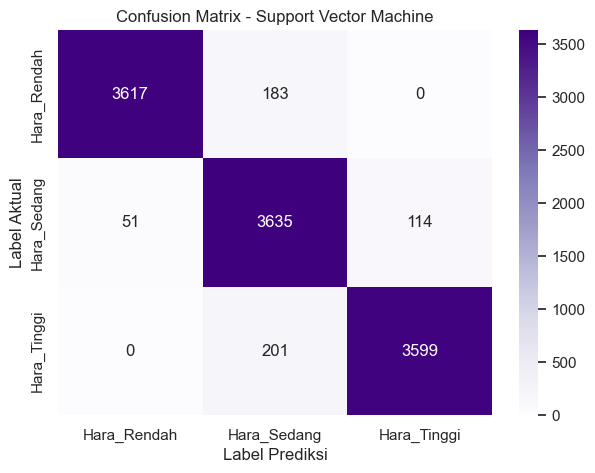

In [26]:
plt.figure(figsize=(7, 5))
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples', xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
plt.title('Confusion Matrix - Support Vector Machine')
plt.ylabel('Label Aktual')
plt.xlabel('Label Prediksi')
plt.show()

100%|██████████| 50/50 [02:33<00:00,  3.07s/it]


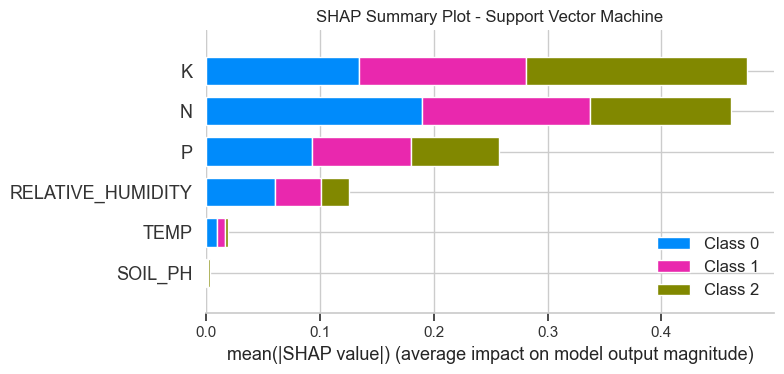

In [27]:
background_svm = shap.sample(X_train, 100)
explainer_svm = shap.KernelExplainer(svm_model.predict_proba, background_svm)
shap_values_svm = explainer_svm.shap_values(X_test[:50]) # Dibatasi 50 sampel data uji agar komputasi efisien

plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot - Support Vector Machine")
shap.summary_plot(shap_values_svm, X_test[:50], plot_type="bar")

In [28]:
# Cell: Menghitung Mean N, P, K, pH, dan Suhu per Kelas Rekomendasi Dosis
kolom_analisis = ['N', 'P', 'K', 'SOIL_PH', 'TEMP', 'REKOMENDASI_PUPUK']

# Menampilkan nilai rata-rata (mean) dari setiap parameter sensor berdasarkan kelas dosis pupuk
df_mean_dosis = df_clean[kolom_analisis].groupby('REKOMENDASI_PUPUK').mean().round(2)

print("--- RATA-RATA (MEAN) N, P, K, pH, & TEMP PER KELAS DOSIS ---")
display(df_mean_dosis)

--- RATA-RATA (MEAN) N, P, K, pH, & TEMP PER KELAS DOSIS ---


,N,P,K,SOIL_PH,TEMP
REKOMENDASI_PUPUK,,,,,
"Dosis Rendah -> Majemuk: NPK 15-10-12 (250 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 56, KCl 56 kg/ha",113.09,64.55,88.28,6.59,23.78
"Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/ha) + Urea (250 kg/ha) | Tunggal: Urea 350, SP-36 75, KCl 75 kg/ha",84.32,49.70,51.19,6.61,24.34
"Dosis Tinggi -> Majemuk: NPK 15-10-12 (400 kg/ha) + Urea (225 kg/ha) | Tunggal: Urea 350, SP-36 94, KCl 94 kg/ha",46.44,30.34,30.34,6.67,26.14


In [29]:
# Cell: Menambahkan Satuan pada Nama Kolom Sensor
df_clean = df_clean.rename(columns={
    'N': 'N (mg/kg)',
    'P': 'P (mg/kg)',
    'K': 'K (mg/kg)',
    'SOIL_PH': 'SOIL_PH (pH)',
    'TEMP': 'TEMP (°C)',
    'RELATIVE_HUMIDITY': 'RELATIVE_HUMIDITY (%)'
})

# Menyimpan kembali ke file CSV yang telah diperbarui
df_clean.to_csv(r"C:\Pupuk\data\Crop_recommendation_labeled_BPSI.csv", index=False)

# Menampilkan 5 baris pertama untuk memastikan perubahan nama kolom berhasil
display(df_clean.head())

,N (mg/kg),P (mg/kg),K (mg/kg),SOIL_PH (pH),TEMP (°C),RELATIVE_HUMIDITY (%),SKOR_HARA_EFEKTIF,STATUS_HARA,REKOMENDASI_PUPUK
0,82.4,40.7,42.2,7.6,26.9,73.8,46.628546,Hara_Sedang,Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/...
1,90.5,51.3,46.2,6.2,35.8,60.9,48.827290,Hara_Sedang,Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/...
2,86.2,50.7,44.4,6.7,34.9,67.5,50.050273,Hara_Sedang,Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/...
3,91.3,51.3,44.5,6.1,28.3,73.6,56.143872,Hara_Sedang,Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/...
4,81.3,48.6,51.0,8.0,26.3,60.3,46.006144,Hara_Sedang,Dosis Sedang -> Majemuk: NPK 15-10-12 (300 kg/...


# Save Model

In [30]:
# Cell: Menyimpan Model Random Forest ke File
import joblib

# Menentukan lokasi dan nama file penyimpanan model
model_path = r"C:\Pupuk\models\random_forest_model.pkl"

# Menyimpan objek rf_model yang sudah ditraining
joblib.dump(rf_model, model_path)

print(f"Model Random Forest berhasil disimpan di: {model_path}")

Model Random Forest berhasil disimpan di: C:\Pupuk\models\random_forest_model.pkl


In [31]:
# Cell: Memuat Kembali Model yang Telah Disimpan
loaded_rf_model = joblib.load(r"C:\Pupuk\models\random_forest_model.pkl")
print("Model Random Forest berhasil dimuat dan siap digunakan kembali!")

Model Random Forest berhasil dimuat dan siap digunakan kembali!


In [ ]:
# %% [markdown]
# # Tabel Rentang Minimum - Maksimum Sensor per Rekomendasi Dosis (df_clean)

# %%
import pandas as pd
import numpy as np

# 1. Mendefinisikan kolom sensor berdasarkan df_clean
kolom_eda = ['N (mg/kg)', 'P (mg/kg)', 'K (mg/kg)', 'SOIL_PH (pH)', 'TEMP (°C)', 'RELATIVE_HUMIDITY (%)']

# 2. Menghitung nilai minimum dan maksimum dengan mengelompokkan berdasarkan REKOMENDASI_PUPUK
summary_min = df_clean.groupby('REKOMENDASI_PUPUK')[kolom_eda].min().round(2)
summary_max = df_clean.groupby('REKOMENDASI_PUPUK')[kolom_eda].max().round(2)

# 3. Menggabungkan hasil ke dalam satu format tabel teks (Min - Max)
tabel_min_max = summary_min.astype(str) + " - " + summary_max.astype(str)

# 4. Menampilkan hasil
print("--- TABEL RENTANG (MIN - MAX) DATA SENSOR ---")
display(tabel_min_max)

KeyError: 'KATEGORI_DOSIS'